# GNAR-Python: a guided tour

This notebook walks through everything the `gnar` package can do, and collects the important facts in one place.

**What is a GNAR process?** A *Generalised Network Autoregressive* process (Knight, Leeming, Nason & Nunes, JSS 2020) is a multivariate time series $X_t \in \mathbb{R}^d$ where each component lives on a **node** of a known graph. Each node is driven by its own past and by the past of its **$r$-stage neighbours**: the nodes exactly $r$ hops away.

$$
X_{i,t} = \sum_{j=1}^{p} \Big( \alpha_{i,j} X_{i,t-j} + \sum_{r=1}^{s_j} \beta_{j,r} \sum_{q \in \mathcal{N}^{(r)}(i)} \omega^{(r)}_{q,i}\, X_{q,t-j} \Big) + \varepsilon_{i,t}
$$

* $p$ is the number of lags; $s = (s_1,\dots,s_p)$ is the **maximum neighbour stage** used at each lag.
* $\omega^{(r)}_{q,i}$ are normalised weights, so for each node $i$ and stage $r$ they sum to 1. In other words, each $\beta$ multiplies a *weighted average* of the $r$-stage neighbours.
* $\varepsilon_t \sim N(0, \Sigma)$.

**Model types** (`model_type`) control which parameters are shared across nodes:

| `model_type` | $\alpha$ (own lags) | $\beta$ (neighbour effects) | # parameters |
|---|---|---|---|
| `"global"` | shared | shared | $p + \sum s$ |
| `"standard"` (local-$\alpha$, the default) | node-specific | shared | $dp + \sum s$ |
| `"local"` (local-$\alpha\beta$) | node-specific | node-specific | $d(p + \sum s)$ |

Compare that with an unrestricted VAR($p$), which has $pd^2$ parameters. Sharing parameters through the graph is what makes GNAR parsimonious.

### Package layout

| Module | Contents |
|---|---|
| `gnar/gnar.py` | `GNAR` class: fit, predict, simulate, AIC/BIC, `to_var`, autocovariances, drawing |
| `gnar/var.py` | `VAR` class: fit, predict, simulate, stationarity, companion form, autocovariances, AIC/BIC |
| `gnar/utils/neighbour_sets.py` | Stage-$r$ neighbour weight matrices for unweighted, weighted and distance networks |
| `gnar/utils/gnar_linear_regression.py` | OLS estimation |
| `gnar/utils/gnar_yule_walker.py` | Yule–Walker estimation |
| `gnar/utils/forecasting.py`, `simulating.py` | Design-matrix bookkeeping for multi-step forecasts and simulation |
| `gnar/utils/data_utils.py` | Input validation, parameter reordering, mean and covariance helpers |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import warnings

from gnar import GNAR, VAR
from gnar.utils.neighbour_sets import neighbour_set_mats, compute_neighbour_sums

np.set_printoptions(precision=3, suppress=True)
pd.set_option("display.precision", 3)
# The package draws random numbers from NumPy's *global* RNG, so seed it with np.random.seed
np.random.seed(2024)

## 1. Networks and neighbour sets

The graph is passed as a square NumPy adjacency matrix `A`. **Convention:** `A[i, j] != 0` means there is an edge $i \to j$, so node $i$'s past influences node $j$. For undirected graphs, just use a symmetric `A`.

`neighbour_set_mats(A, r, net_type)` returns an array of shape `(r, d, d)`. **Column $j$** of the stage-$k$ matrix holds the weights $\omega^{(k)}_{\cdot, j}$ that node $j$ puts on its $k$-stage neighbours. Neighbour sums are then simply `ts @ ns_mats[k]`.

Stage $k$ means the shortest-path distance is exactly $k$. How weights are computed depends on `net_type`:

| `net_type` | Meaning of `A` entries | Weights within stage $k$ |
|---|---|---|
| `"unweighted"` (default) | 0/1 only (validated) | uniform: $1/|\mathcal N^{(k)}(j)|$ |
| `"weighted"` | connection strength (bigger = stronger) | proportional to $\sum_{\text{shortest paths}} \prod$ edge weights |
| `"distance"` | distance (bigger = farther) | as `"weighted"` after mapping $d_{ij} \mapsto 1/d_{ij}$ |

Let's build a small 6-node network and look at its stage-1 and stage-2 neighbour weights.

In [2]:
# 6-node undirected network: a ring 0-1-2-3-4-5-0 plus a chord 0-3
edges = [(0, 1), (1, 2), (2, 3), (3, 4), (4, 5), (5, 0), (0, 3)]
d = 6
A = np.zeros((d, d))
for i, j in edges:
    A[i, j] = A[j, i] = 1

ns = neighbour_set_mats(A, r=2, net_type="unweighted")
print("ns_mats shape:", ns.shape)
print("Stage-1 weights (column j = weights used by node j):\n", ns[0])
print("Stage-2 weights:\n", ns[1])
print("Columns sum to 1:", ns.sum(axis=1))

ns_mats shape: (2, 6, 6)
Stage-1 weights (column j = weights used by node j):
 [[0.    0.5   0.    0.333 0.    0.5  ]
 [0.333 0.    0.5   0.    0.    0.   ]
 [0.    0.5   0.    0.333 0.    0.   ]
 [0.333 0.    0.5   0.    0.5   0.   ]
 [0.    0.    0.    0.333 0.    0.5  ]
 [0.333 0.    0.    0.    0.5   0.   ]]
Stage-2 weights:
 [[0.  0.  0.5 0.  0.5 0. ]
 [0.  0.  0.  0.5 0.  0.5]
 [0.5 0.  0.  0.  0.5 0. ]
 [0.  0.5 0.  0.  0.  0.5]
 [0.5 0.  0.5 0.  0.  0. ]
 [0.  0.5 0.  0.5 0.  0. ]]
Columns sum to 1: [[1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1.]]


Now the same topology with **weights** (connection strengths) and with **distances**. With weights, a stronger edge gets a larger share. With distances, a shorter edge gets a larger share. For stage 2 the weights come from products of edge weights along every shortest path.

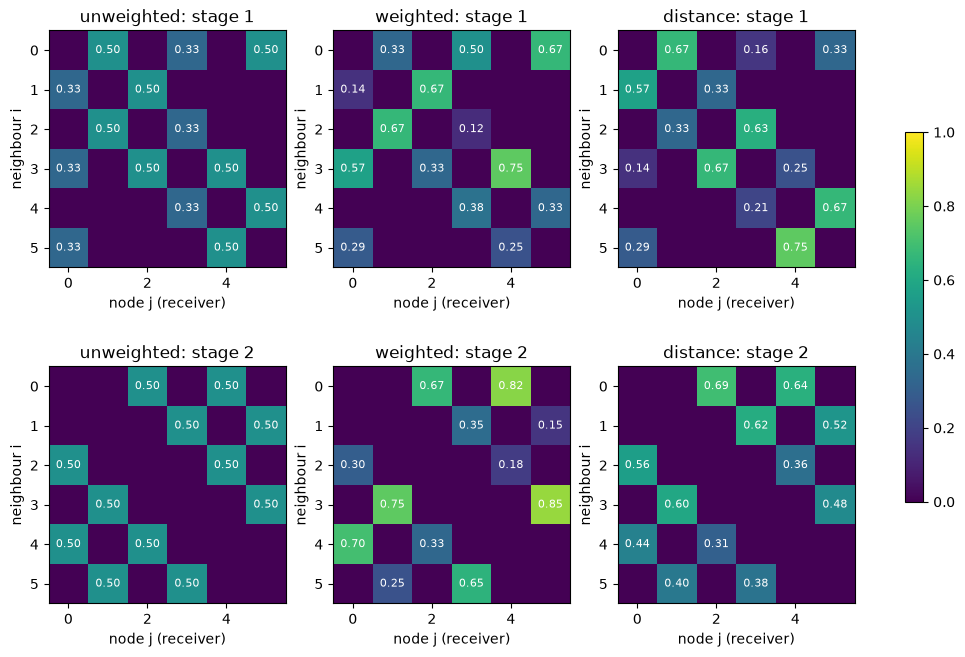

In [3]:
w = {(0, 1): 1, (1, 2): 2, (2, 3): 1, (3, 4): 3, (4, 5): 1, (5, 0): 2, (0, 3): 4}
A_w = np.zeros((d, d))
for (i, j), v in w.items():
    A_w[i, j] = A_w[j, i] = v

fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for col, nt in enumerate(["unweighted", "weighted", "distance"]):
    M = neighbour_set_mats(A if nt == "unweighted" else A_w, r=2, net_type=nt)
    for row in range(2):
        ax = axes[row, col]
        im = ax.imshow(M[row], cmap="viridis", vmin=0, vmax=1)
        ax.set_title(f"{nt}: stage {row + 1}")
        ax.set_xlabel("node j (receiver)"); ax.set_ylabel("neighbour i")
        for (i, j), val in np.ndenumerate(M[row]):
            if val > 0:
                ax.text(j, i, f"{val:.2f}", ha="center", va="center", color="w", fontsize=8)
fig.colorbar(im, ax=axes, shrink=0.6)
plt.show()

For example, node 0's stage-1 neighbours are {1, 3, 5}. They get equal weight when unweighted. Weighted, they get $(1, 4, 2)/7$. As distances, they get $(1, \tfrac14, \tfrac12)/1.75$.

## 2. Specifying a model from known parameters

A `GNAR` object can be built in two ways: by **fitting** (`ts=...`) or by **giving parameters** (`coeffs=...`). For the second, you need the coefficient matrix layout:

* `coeffs` has shape **`(p + sum(s), d)`**, one column per node.
* Rows `0 … p-1` are $\alpha_1,\dots,\alpha_p$.
* Then come the $\beta$s **grouped by lag**: $\beta_{1,1},\dots,\beta_{1,s_1},\ \beta_{2,1},\dots,\beta_{2,s_2},\dots$
* The constructor checks that the coefficients have the sharing pattern of `model_type`. For `global`, every row must be constant. For `standard`, the $\beta$ rows must be constant.
* `mean` is a scalar or length-`d` array. `sigma_2` is a scalar (iid noise), a length-`d` vector (independent noise with per-node variances), or a `d×d` covariance matrix.
* If you pass `coeffs` as a `DataFrame`, its column names become node names in printing, plotting and forecasts.

Below is a **standard GNAR(2, [2, 1])** on our network. Each node has its own $\alpha$s, and the neighbour effects $\beta_{1,1}, \beta_{1,2}, \beta_{2,1}$ are shared.

In [4]:
p, s = 2, np.array([2, 1])
names = [f"N{i}" for i in range(d)]

alpha1 = np.array([0.30, 0.25, 0.20, 0.35, 0.15, 0.25])
alpha2 = np.array([-0.10, 0.05, 0.00, -0.05, 0.10, 0.00])
beta11, beta12, beta21 = 0.25, 0.10, -0.10
true_coeffs = np.vstack([alpha1, alpha2,
                         np.full(d, beta11), np.full(d, beta12), np.full(d, beta21)])

G_true = GNAR(A, p=p, s=s, model_type="standard",
              coeffs=pd.DataFrame(true_coeffs, columns=names),
              mean=np.linspace(-1, 1, d), sigma_2=1.0)
print(repr(G_true))
print(G_true)

GNAR(model_type="standard", net_type="unweighted", p=2, s=[2, 1], d=6, fitted=False)
Standard GNAR(2, [2 1]) Model
Graph with 6 nodes and 7 edges
Parameters:
         N0    N1    N2    N3    N4    N5
mean  -1.00 -0.60 -0.20  0.20  0.60  1.00
a_1    0.30  0.25  0.20  0.35  0.15  0.25
a_2   -0.10  0.05  0.00 -0.05  0.10  0.00
b_1,1  0.25  0.25  0.25  0.25  0.25  0.25
b_1,2  0.10  0.10  0.10  0.10  0.10  0.10
b_2,1 -0.10 -0.10 -0.10 -0.10 -0.10 -0.10
Noise covariance matrix:
     N0   N1   N2   N3   N4   N5
N0  1.0  0.0  0.0  0.0  0.0  0.0
N1  0.0  1.0  0.0  0.0  0.0  0.0
N2  0.0  0.0  1.0  0.0  0.0  0.0
N3  0.0  0.0  0.0  1.0  0.0  0.0
N4  0.0  0.0  0.0  0.0  1.0  0.0
N5  0.0  0.0  0.0  0.0  0.0  1.0



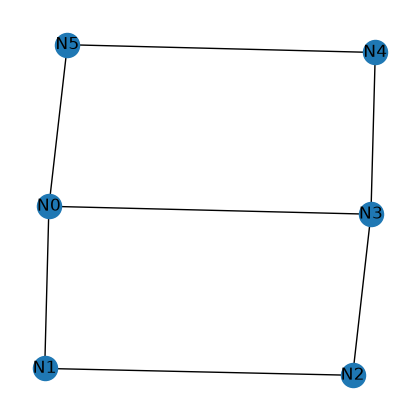

In [5]:
plt.figure(figsize=(4, 4))
G_true.draw()          # thin wrapper around networkx.draw on to_networkx()
plt.show()

**Stationarity.** `G.is_stationary()` checks the companion form of the equivalent VAR. When a model is built from parameters, the constructor warns if it is non-stationary. A simple sufficient condition for global-$\alpha$ models is $\sum_j(|\alpha_j| + \sum_r |\beta_{j,r}|) < 1$.

In [6]:
print("Stationary?", G_true.is_stationary())

Stationary? True


## 3. Simulation

`G.simulate(n, sigma_2=None, burn_in=50)` returns an `(n, d)` NumPy array. The recursion starts from a zero pre-sample of `p` rows, which is always discarded, and then the first `burn_in` simulated steps are dropped. You can override the noise variance per call with `sigma_2`, which takes the same formats as above. Noise comes from the global `np.random` state.

(1500, 6)


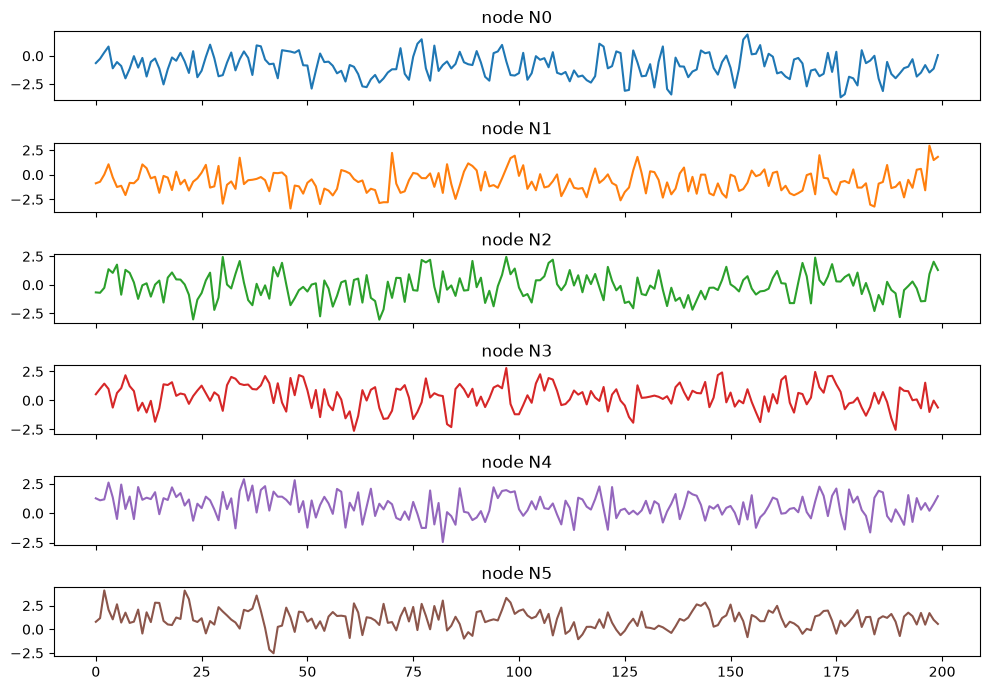

In [7]:
np.random.seed(1)
ts_sim = G_true.simulate(1500, burn_in=200)
ts_df = pd.DataFrame(ts_sim, columns=names)
print(ts_df.shape)

ts_df.iloc[:200].plot(subplots=True, figsize=(10, 7), legend=False, sharex=True,
                      title=[f"node {c}" for c in names])
plt.tight_layout(); plt.show()

## 4. Fitting

Pass `ts` (a NumPy array or `DataFrame` of shape `(n, d)`) to the constructor, or call `G.fit(ts, demean=True, method="OLS")` on an existing object.

* `method="OLS"` (default) is least squares. `global` and `local` models use `scipy.linalg.lstsq`. The `standard` model stacks all nodes into one sparse system and solves it with `scipy.sparse.linalg.lsqr`, using tight tolerances.
* `method="YW"` uses the GNAR Yule–Walker equations, built from sample autocovariances mapped through the neighbour weights.
* `demean=True` subtracts the sample mean of each node, which is stored in `G.mu`.
* After fitting you get `G.coeffs` (shape `(p+sum(s), d)`), `G.mu` (shape `(1, d)`) and `G.sigma_2`, the `d×d` residual covariance $\hat\varepsilon^\top\hat\varepsilon/(n-p)$.
* `s` may contain zeros. With `s = [0, ..., 0]` the model reduces to node-wise AR($p$) models.
* If a coefficient has no data behind it, for example a $\beta$ for an isolated node, it is set to 0.

Let's recover the true parameters from the simulated data.

In [8]:
G_ols = GNAR(A, p=2, s=np.array([2, 1]), ts=ts_df, model_type="standard", method="OLS")
G_yw  = GNAR(A, p=2, s=np.array([2, 1]), ts=ts_df, model_type="standard", method="YW")

idx = ["a_1", "a_2", "b_1,1", "b_1,2", "b_2,1"]
compare = pd.concat({"true": pd.DataFrame(true_coeffs, index=idx, columns=names),
                     "OLS": pd.DataFrame(G_ols.coeffs, index=idx, columns=names),
                     "YW":  pd.DataFrame(G_yw.coeffs, index=idx, columns=names)}, axis=1)
compare.T.round(3)

a_1    a_2  b_1,1  b_1,2  b_2,1
true N0  0.300 -0.100  0.250  0.100 -0.100
     N1  0.250  0.050  0.250  0.100 -0.100
     N2  0.200  0.000  0.250  0.100 -0.100
     N3  0.350 -0.050  0.250  0.100 -0.100
     N4  0.150  0.100  0.250  0.100 -0.100
     N5  0.250  0.000  0.250  0.100 -0.100
OLS  N0  0.321 -0.140  0.252  0.118 -0.083
     N1  0.277  0.026  0.252  0.118 -0.083
     N2  0.205  0.011  0.252  0.118 -0.083
     N3  0.342 -0.037  0.252  0.118 -0.083
     N4  0.154  0.062  0.252  0.118 -0.083
     N5  0.283 -0.049  0.252  0.118 -0.083
YW   N0  0.321 -0.139  0.252  0.119 -0.083
     N1  0.277  0.026  0.252  0.119 -0.083
     N2  0.205  0.011  0.252  0.119 -0.083
     N3  0.343 -0.037  0.252  0.119 -0.083
     N4  0.154  0.062  0.252  0.119 -0.083
     N5  0.283 -0.049  0.252  0.119 -0.083

In [9]:
print("Estimated means:", G_ols.mu.round(2), "\nTrue means:     ", G_true.mu.round(2))
print("\nEstimated noise covariance (true = I):\n", G_ols.sigma_2.round(2))

Estimated means: [[-0.97 -0.58 -0.17  0.24  0.61  0.98]] 
True means:      [[-1.  -0.6 -0.2  0.2  0.6  1. ]]

Estimated noise covariance (true = I):
 [[ 1.03 -0.04 -0.04  0.01 -0.01  0.03]
 [-0.04  1.    0.02 -0.02  0.    0.01]
 [-0.04  0.02  0.97 -0.02  0.05 -0.02]
 [ 0.01 -0.02 -0.02  0.97 -0.   -0.02]
 [-0.01  0.    0.05 -0.    1.03 -0.01]
 [ 0.03  0.01 -0.02 -0.02 -0.01  0.99]]


### Comparing model types
The same data fit with each `model_type`. The `global` model forces one $\alpha$ for all nodes. The `local` model gives every node its own $\beta$s.

In [10]:
for mt in ["global", "standard", "local"]:
    Gm = GNAR(A, p=2, s=np.array([2, 1]), ts=ts_df, model_type=mt)
    print(f"--- {mt:8s}  #params={Gm._num_params():3d}  BIC={Gm.bic():.4f}")
    print(pd.DataFrame(Gm.coeffs, index=idx, columns=names).round(3), "\n")

--- global    #params=  5  BIC=0.0472
          N0     N1     N2     N3     N4     N5
a_1    0.262  0.262  0.262  0.262  0.262  0.262
a_2   -0.018 -0.018 -0.018 -0.018 -0.018 -0.018
b_1,1  0.253  0.253  0.253  0.253  0.253  0.253
b_1,2  0.118  0.118  0.118  0.118  0.118  0.118
b_2,1 -0.086 -0.086 -0.086 -0.086 -0.086 -0.086 

--- standard  #params= 15  BIC=0.0489
          N0     N1     N2     N3     N4     N5
a_1    0.321  0.277  0.205  0.342  0.154  0.283
a_2   -0.140  0.026  0.011 -0.037  0.062 -0.049
b_1,1  0.252  0.252  0.252  0.252  0.252  0.252
b_1,2  0.118  0.118  0.118  0.118  0.118  0.118
b_2,1 -0.083 -0.083 -0.083 -0.083 -0.083 -0.083 

--- local     #params= 30  BIC=0.1104
          N0     N1     N2     N3     N4     N5
a_1    0.314  0.280  0.211  0.347  0.149  0.282
a_2   -0.144  0.023  0.015 -0.037  0.057 -0.044
b_1,1  0.247  0.267  0.252  0.292  0.277  0.185
b_1,2  0.119  0.156  0.085  0.098  0.119  0.132
b_2,1  0.004 -0.128 -0.118 -0.140 -0.060 -0.050 



The data come from a *standard* model, yet BIC slightly prefers *global* here. The true node-specific $\alpha$s differ only modestly, so pooling them costs less in fit than the 10 extra parameters cost in penalty. The *local* model is clearly over-parameterised. The shared $\beta$s are estimated well by all three.

## 5. Model selection with AIC / BIC

`G.aic()` and `G.bic()` are only available for fitted models. Built from parameters, they raise `ValueError`. They use the multivariate-Gaussian forms

$$\text{BIC} = \log|\hat\Sigma| + k\frac{\log(n-p)}{n-p}, \qquad \text{AIC} = \log|\hat\Sigma| + \frac{2k}{n-p},$$

where $k$ is the parameter count for the model type. Let's search over lag orders and neighbour stages.

In [11]:
rows = []
for p_ in [1, 2, 3]:
    for s_max in [1, 2, 3]:
        for s_vec in {tuple([s_max] * p_), tuple([s_max] + [1] * (p_ - 1))}:
            s_arr = np.array(s_vec)
            Gm = GNAR(A, p=p_, s=s_arr, ts=ts_df, model_type="standard")
            rows.append({"p": p_, "s": list(s_vec), "BIC": Gm.bic(), "AIC": Gm.aic()})
sel = pd.DataFrame(rows).sort_values("BIC").reset_index(drop=True)
sel.head(8)

,p,s,BIC,AIC
0,2,"[2, 1]",0.049,-4.267e-03
1,2,"[2, 2]",0.052,-4.434e-03
2,2,"[3, 1]",0.054,-2.928e-03
3,1,[2],0.060,3.147e-02
4,2,"[3, 3]",0.062,-1.821e-03
5,1,[3],0.065,3.272e-02
6,3,"[2, 1, 1]",0.078,1.752e-04
7,3,"[3, 1, 1]",0.083,1.515e-03


The BIC should rank the true order, GNAR(2, [2, 1]), at or near the top.

## 6. Forecasting

`G.predict(ts=None, h=1)` produces $1,\dots,h$-step-ahead forecasts. The output shape depends on the input:

| Input `ts` | Output |
|---|---|
| `None` | forecasts from the last `p` observations used in fitting (needs a fitted model) |
| exactly `p` rows | array `(h, d)`, or DataFrame indexed `1..h` |
| `n > p` rows, NumPy | array `(n-p+1, d, h)`: forecasts from **every** origin $t = p,\dots,n$ |
| `n > p` rows, DataFrame | DataFrame `(n-p+1, d*h)` with MultiIndex columns `(node, "h = k")`, indexed by origin time |

Being able to forecast from every origin makes rolling out-of-sample evaluation a single call. Forecasts are always on the original (non-demeaned) scale.

In [12]:
np.random.seed(7)
train, test = ts_df.iloc[:1000], ts_df.iloc[1000:]
G_fit = GNAR(A, p=2, s=np.array([2, 1]), ts=train, model_type="standard")

print("Forecast from end of training data (DataFrame in -> DataFrame out):")
display(G_fit.predict(h=3))

print("Forecast from exactly p rows of a NumPy array -> shape", G_fit.predict(test.to_numpy()[:2], h=3).shape)
print("Forecast from every origin in a NumPy array  -> shape", G_fit.predict(test.to_numpy(), h=3).shape)

Forecast from end of training data (DataFrame in -> DataFrame out):


,N0,N1,N2,N3,N4,N5
1,-1.178,-0.887,-0.207,0.495,0.726,0.993
2,-0.907,-0.762,-0.176,0.259,0.626,0.973
3,-0.929,-0.667,-0.191,0.236,0.643,0.969


Forecast from exactly p rows of a NumPy array -> shape (3, 6)


Forecast from every origin in a NumPy array  -> shape (499, 6, 3)


In [13]:
# Rolling out-of-sample evaluation: forecasts from every origin in the test set
h = 5
fc = G_fit.predict(test, h=h)            # MultiIndex columns (node, "h = k")
print(fc.iloc[:3, :6])

# Compare GNAR vs an unrestricted VAR(2) vs the training-mean benchmark
V_fit = VAR(p=2, ts=train)
fc_var = V_fit.predict(test.to_numpy(), h=h)          # (n-p+1, d, h)
fc_gnar = G_fit.predict(test.to_numpy(), h=h)
y = test.to_numpy()
p_ = 2
mse = {"GNAR(2,[2,1])": [], "VAR(2)": [], "mean": []}
for k in range(1, h + 1):
    # the forecast made at origin index o (last obs = row o + p - 1) targets row o + p - 1 + k
    n_orig = len(y) - p_ + 1 - k
    target = y[p_ - 1 + k : p_ - 1 + k + n_orig]
    mse["GNAR(2,[2,1])"].append(np.mean((fc_gnar[:n_orig, :, k - 1] - target) ** 2))
    mse["VAR(2)"].append(np.mean((fc_var[:n_orig, :, k - 1] - target) ** 2))
    mse["mean"].append(np.mean((train.mean().to_numpy() - target) ** 2))
mse = pd.DataFrame(mse, index=[f"h={k}" for k in range(1, h + 1)])
print(f"\nGNAR params: {G_fit._num_params()},  VAR params: {2 * d * d}")
mse

         N0                                 N1
      h = 1  h = 2  h = 3  h = 4  h = 5  h = 1
1001 -1.633 -1.133 -0.949 -0.956 -0.982 -1.054
1002 -1.903 -0.888 -0.828 -0.957 -1.003 -1.106
1003 -1.187 -0.752 -0.882 -0.991 -1.004 -1.248

GNAR params: 15,  VAR params: 72


,"GNAR(2,[2,1])",VAR(2),mean
h=1,0.999,1.009,1.116
h=2,1.099,1.107,1.114
h=3,1.112,1.115,1.113
h=4,1.113,1.116,1.113
h=5,1.114,1.115,1.114


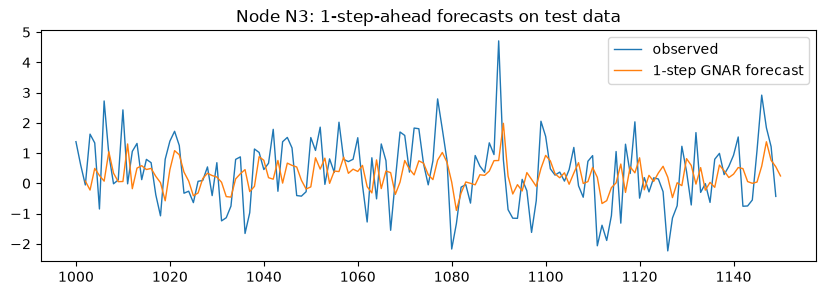

In [14]:
# Visualise 1-step forecasts for one node
node = "N3"
one_step = fc[(node, "h = 1")]
plt.figure(figsize=(10, 3))
plt.plot(test.index[:150], test[node].iloc[:150], label="observed", lw=1)
# the forecast made at origin t is for t + 1
plt.plot(one_step.index[:149] + 1, one_step.iloc[:149], label="1-step GNAR forecast", lw=1)
plt.legend(); plt.title(f"Node {node}: 1-step-ahead forecasts on test data"); plt.show()

## 7. GNAR ↔ VAR and the `VAR` class

Every GNAR($p$, $s$) is a VAR($p$) with structured coefficients $\Phi_j = \operatorname{diag}(\alpha_{\cdot,j}) + \sum_r \beta_{j,r} W^{(r)\top}$. `G.to_var()` returns the equivalent `VAR` object, which gives you:

* `is_stationary()`: are all eigenvalues of the companion matrix inside the unit circle?
* `companion_form()`: returns `(Phi, Sigma)` of the $dp$-dimensional VAR(1).
* `compute_autocov_mats(max_lag)` and `compute_autocorr_mats(max_lag)`: theoretical $\Gamma(0..\text{max\_lag})$, where $\Gamma(k) = E[X_t X_{t-k}^\top]$. These are also available directly on `GNAR`.

`VAR` objects store coefficients as a `(p*d, d)` matrix. Row `(j-1)*d + i` is the effect of node `i` at lag `j`, and column `k` is the target node. The constructor warns when the parameters are non-stationary. `VAR` can also be fit directly (`VAR(p, ts=...)`), and has `predict`, `simulate`, `aic` and `bic` with the same semantics as `GNAR`.

In [15]:
V_true = G_true.to_var()
print(repr(V_true))
Phi1 = V_true.coeffs[:d].T          # lag-1 coefficient matrix (target x source)
print("Lag-1 VAR matrix implied by the GNAR (sparsity follows the graph + 2-stage neighbours):\n", Phi1)
phi, _ = V_true.companion_form()
print("\nLargest |eigenvalue| of companion matrix:", np.abs(np.linalg.eigvals(phi)).max().round(3))

VAR(p=2, d=6, fitted=False)
Lag-1 VAR matrix implied by the GNAR (sparsity follows the graph + 2-stage neighbours):
 [[0.3   0.083 0.05  0.083 0.05  0.083]
 [0.125 0.25  0.125 0.05  0.    0.05 ]
 [0.05  0.125 0.2   0.125 0.05  0.   ]
 [0.083 0.05  0.083 0.35  0.083 0.05 ]
 [0.05  0.    0.05  0.125 0.15  0.125]
 [0.125 0.05  0.    0.05  0.125 0.25 ]]

Largest |eigenvalue| of companion matrix: 0.418


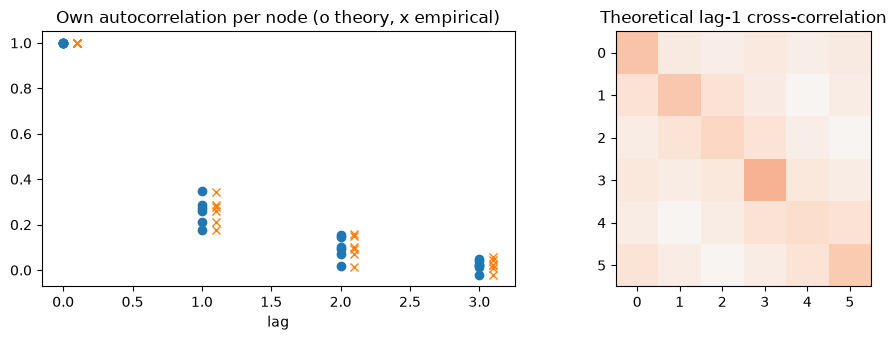

Max |theory - empirical| over lags 0..3: 0.015


In [16]:
# Theoretical vs empirical autocorrelation, using a long simulation
np.random.seed(3)
long = G_true.simulate(50_000)
long_c = long - long.mean(0)
emp = np.array([long_c[k:].T @ long_c[:len(long_c) - k] / len(long_c) for k in range(4)])
emp = emp / np.sqrt(np.outer(np.diag(emp[0]), np.diag(emp[0])))
theo = G_true.compute_autocorr_mats(max_lag=3)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for k in range(4):
    ax[0].plot(np.diag(theo[k]) * 0 + k, np.diag(theo[k]), "o", color="C0")
    ax[0].plot(np.diag(emp[k]) * 0 + k + 0.1, np.diag(emp[k]), "x", color="C1")
ax[0].set_title("Own autocorrelation per node (o theory, x empirical)"); ax[0].set_xlabel("lag")
ax[1].imshow(theo[1], cmap="RdBu_r", vmin=-1, vmax=1); ax[1].set_title("Theoretical lag-1 cross-correlation")
plt.tight_layout(); plt.show()
print("Max |theory - empirical| over lags 0..3:", np.abs(theo - emp).max().round(3))

In [17]:
# Sanity check: GNAR and its VAR form give identical forecasts and (with the same seed) identical simulations
x = ts_sim[:20]
print("max forecast diff:", np.abs(G_true.predict(x, h=4) - V_true.predict(x, h=4)).max())
np.random.seed(0); a = G_true.simulate(100)
np.random.seed(0); b = V_true.simulate(100)
print("max simulation diff:", np.abs(a - b).max())

max forecast diff: 2.220446049250313e-16
max simulation diff: 4.440892098500626e-16


## 8. Weighted, distance and directed networks

Only the neighbour-weight matrices change, so fitting, forecasting and simulation all work the same way. Here we simulate on the **weighted** network and check that the correct `net_type` is preferred by BIC. Directed graphs work too: just use a non-symmetric `A`.

In [18]:
np.random.seed(11)
Gw_true = GNAR(A_w, p=1, s=np.array([2]), net_type="weighted", model_type="global",
               coeffs=np.tile([[0.3], [0.4], [0.15]], (1, d)), sigma_2=1.0)
ts_w = Gw_true.simulate(3000)

for nt, AA in [("unweighted", A), ("weighted", A_w), ("distance", A_w)]:
    Gm = GNAR(AA, p=1, s=np.array([2]), ts=ts_w, net_type=nt, model_type="global")
    print(f"{nt:10s} BIC={Gm.bic():.4f}  coeffs={Gm.coeffs[:, 0].round(3)}")
print("true coeffs:", Gw_true.coeffs[:, 0])

unweighted BIC=0.0765  coeffs=[0.297 0.41  0.145]
weighted   BIC=-0.0210  coeffs=[0.291 0.403 0.157]
distance   BIC=0.2819  coeffs=[0.322 0.313 0.176]
true coeffs: [0.3  0.4  0.15]


In [19]:
# A directed network: edges i -> j mean i drives j. Node 0 is a pure source here.
A_dir = np.zeros((4, 4))
for i, j in [(0, 1), (1, 2), (2, 3), (0, 2)]:
    A_dir[i, j] = 1
print("Stage-1 weights:\n", neighbour_set_mats(A_dir, 2)[0])
G_dir = GNAR(A_dir, p=1, s=np.array([1]), model_type="global", coeffs=np.tile([[0.4], [0.5]], (1, 4)))
print("Implied VAR lag-1 matrix (row = target, col = source):\n", G_dir.to_var().coeffs.T)

Stage-1 weights:
 [[0.  1.  0.5 0. ]
 [0.  0.  0.5 0. ]
 [0.  0.  0.  1. ]
 [0.  0.  0.  0. ]]
Implied VAR lag-1 matrix (row = target, col = source):
 [[0.4  0.   0.   0.  ]
 [0.5  0.4  0.   0.  ]
 [0.25 0.25 0.4  0.  ]
 [0.   0.   0.5  0.4 ]]


## 9. Bugs found and fixed during review

The core mathematics was sound from the start. For every model type and network type, GNAR forecasts and simulations match the implied VAR to machine precision. OLS and YW agree on large samples, and theoretical autocovariances match long simulations. The review also found the following bugs. All are now fixed and covered by `tests/test_regressions.py`.

| # | Where | Bug (now fixed) |
|---|---|---|
| 1 | `gnar_linear_regression.py::gnar_lr` | OLS residual covariance divided by $n-2p$ instead of $n-p$. This inflated `sigma_2` and biased AIC/BIC. |
| 2 | `gnar_yule_walker.py::format_standard` | YW with `model_type="standard"` crashed when the entries of `s` differed (e.g. `s=[2,1]`). |
| 3 | `neighbour_sets.py::neighbour_set_mats` | `s` all zeros (pure node-wise AR) crashed with `IndexError`. |
| 4 | `var.py::compute_autocov_mats` | Returned `p` matrices instead of `max_lag+1` when `max_lag < p-1`. |
| 5 | `GNAR` / `VAR` docstrings | Gave the wrong `coeffs` shape (`1 + ...`). |
| 6 | `generate_noise`, `set_cov`, `cov_mat` | A NumPy scalar `sigma_2` (e.g. `np.int64(2)`) crashed. |
| 7 | Input validation | Non-integer `s`/`p`, and a `ts` whose number of columns didn't match `A`, gave opaque errors. Now there are clear `ValueError`s, and integer-valued float `s` is accepted. |
| 8 | `GNAR.__init__` | No warning for non-stationary parameters. There is now a warning and a `GNAR.is_stationary()` method. |
| 9 | `GNAR.simulate` / `VAR.simulate` | With `burn_in < p`, the output began with all-zero rows. |
| 10 | `gnar_lr` (standard) | The iterative `lsqr` solver ran with loose default tolerances (~$10^{-6}$). It now matches exact least squares. |

The cell below exercises each fix.

In [20]:
from gnar.utils.gnar_linear_regression import format_X_y

# 1: OLS sigma_2 = RSS / (n - p)
np.random.seed(0)
small = np.random.normal(size=(30, d))
Gm = GNAR(A, p=3, s=np.array([1, 1, 1]), ts=small, model_type="local")
X_, y_ = format_X_y(compute_neighbour_sums(small - Gm.mu, Gm._ns_mats, 1), 3, Gm._s)
res = np.sum(X_ * Gm.coeffs.T, axis=2) - y_
print("1: sigma_2 / [RSS/(n-p)] =", (np.diag(Gm.sigma_2) / np.diag(res.T @ res / 27)).round(6)[:3])

# 2: YW standard with unequal s (also used in section 4)
print("2: YW standard s=[1,0] ->", GNAR(A, p=2, s=np.array([1, 0]), ts=ts_df, method="YW").coeffs.shape)

# 3: pure node-wise AR
G_ar = GNAR(A, p=1, s=np.array([0]), ts=ts_df, model_type="local")
print("3: s=[0] alphas:", G_ar.coeffs[0].round(3))

# 4: autocovariance truncation
print("4: VAR(3).compute_autocov_mats(max_lag=0).shape:",
      VAR(p=3, coeffs=np.vstack([0.2 * np.eye(2)] * 3)).compute_autocov_mats(max_lag=0).shape)

# 6: NumPy scalar noise variance
print("6: simulate(sigma_2=np.int64(2)).shape:", G_true.simulate(5, sigma_2=np.int64(2)).shape)

# 7: clear validation errors
try:
    GNAR(A, p=1, s=np.array([1]), ts=np.random.normal(size=(50, 4)))
except ValueError as e:
    print("7:", e)

# 8: non-stationary parameters now warn
with warnings.catch_warnings(record=True) as wlist:
    warnings.simplefilter("always")
    G_bad = GNAR(A, p=1, s=np.array([1]), coeffs=np.tile([[0.9], [0.5]], (1, d)), model_type="global")
print("8:", wlist[0].message, "| is_stationary():", G_bad.is_stationary())

# 9: no zero pre-sample rows with burn_in=0
np.random.seed(0)
print("9: first row with burn_in=0:", G_true.simulate(3, burn_in=0)[0].round(3))

1: sigma_2 / [RSS/(n-p)] = [1. 1. 1.]
2: YW standard s=[1,0] -> (3, 6)
3: s=[0] alphas: [0.297 0.301 0.224 0.347 0.181 0.29 ]
4: VAR(3).compute_autocov_mats(max_lag=0).shape: (1, 2, 2)
6: simulate(sigma_2=np.int64(2)).shape: (5, 6)
7: The time series has 4 columns but the adjacency matrix has 6 nodes.
8: The GNAR model is non-stationary based on the provided parameters! | is_stationary(): False
9: first row with burn_in=0: [-0.239 -0.478  0.244  0.534  2.094  0.795]


## 10. Cheat sheet

```python
from gnar import GNAR, VAR

# Build from data (OLS or Yule-Walker)
G = GNAR(A, p=2, s=np.array([2, 1]), ts=data, model_type="standard",   # "global" | "standard" | "local"
         net_type="unweighted", method="OLS", demean=True)              # "weighted" | "distance"; "YW"
# ...or from known parameters
G = GNAR(A, p, s, coeffs=C, mean=mu, sigma_2=sig, model_type=..., net_type=...)  # C: (p + sum(s), d)

G.coeffs, G.mu, G.sigma_2          # (p+sum(s), d), (1, d), scalar/vector/(d, d)
G.fit(new_data, demean=True, method="OLS")
G.aic(), G.bic()                   # fitted models only
G.simulate(n, sigma_2=None, burn_in=50)               # -> (n, d) ndarray
G.predict(ts=None, h=1)            # p rows -> (h, d); n rows -> (n-p+1, d, h) or MultiIndex DataFrame
G.to_var()                         # -> VAR: is_stationary(), companion_form(), ...
G.compute_autocov_mats(k), G.compute_autocorr_mats(k)  # (k+1, d, d)
G.to_networkx(), G.draw()
```

**Key facts to remember**

1. `A[i, j]` means $i \to j$. For each stage, the neighbour weights for node $j$ are in **column** $j$ and sum to 1.
2. Stage $r$ means a shortest-path distance of exactly $r$. Weighted and distance networks weight neighbours by products of edge weights (or of inverse distances) along shortest paths.
3. Coefficient rows are $[\alpha_1..\alpha_p,\ \beta_{1,1..s_1},\ \beta_{2,1..s_2},\dots]$. The mean is passed separately.
4. Sharing constraints (`global` / `standard` / `local`) are validated when you pass parameters.
5. Randomness uses `np.random`'s global state, so seed it with `np.random.seed`.
6. GNAR is a parsimonious, graph-structured VAR. `to_var()` gives the exact equivalent model, which you can use for stationarity checks and theoretical autocovariances.
7. `s` may contain zeros, and all estimators support any combination of `model_type`, `net_type` and `s`.